In [1]:
#Modeling LTS array response for barry arm, with a generic spherical dataset
import pyproj
import numpy as np
import pandas as pd



#Generate spherical dataset
#Get UTM baei array center
lat_list = [61.132675, 61.132085, 61.13173, 61.131875, 61.132405, 61.13218]
lon_list = [-148.1219, -148.12107, -148.121985, -148.122915, -148.12281, -148.12206]
elev_list = [591.8, 607.6, 597.6, 584.6, 582.0, 596.2]

#BANI(NEW!) array
#lat_list = [61.138952, 61.138595, 61.138888, 61.138825]
#lon_list = [-148.112629, -148.113351, -148.113541, -148.113146]
#elev_list = [590.0928, 585.8256, 584.9112, 583.9968]


#bais array
"""
bais_stations = {'BAIS.01': (61.11962, -148.158315), 'BAIS.02': (61.119775, -148.157485), 
 'BAIS.03': (61.11939, -148.1579), 'BAIS.04': (61.119575, -148.157775)}
lat_list = [61.11962, 61.119775, 61.11939, 61.119575, ]
lon_list = [-148.158315, -148.157485, -148.1579, -148.157775]
elev_list = [9.5, 9.5, 9.5, 9.5] #REALLY INACCURATE
elev_list = [22.25, 27.09, 21.91, 22.87] #FROM IFSAR DEM
"""
trans = pyproj.Transformer.from_crs("EPSG:4326", "EPSG:32606", always_xy=True) # WGS84 lat long
baei_array = np.vstack([trans.transform(lon_list, lat_list), elev_list])
baei_mean = np.mean(baei_array, axis=1)
print(baei_mean)
C = 334.337 #m/s


radius = 3000
azimuth_angles = np.arange(0, 365, 5)  # every 10 degrees #DOES OVERLAP, GOOD FOR GRID
elevation_angles = np.arange(-20, 50, 5)

def get_spherical_points(azimuth_deg, elevation_deg, r, center=baei_mean):
    """
    azimuth_deg: 1D array of azimuth angles (degrees), clockwise from North
    elevation_deg: 1D array of elevation angles (degrees, 0 = horizontal)
    r: radius from center
    center: (cx, cy, cz)
    Returns: Nx3 array of points
    """
    az = np.deg2rad(90.0 - azimuth_deg) #match weird pyvista/dem thing. same as in set_camera_angles
    el = np.deg2rad(elevation_deg)
    points = []

    for e, degrees_e in zip(el, elevation_deg):
        for a, degrees_a in zip(az, azimuth_deg):

            x = center[0] + r * np.cos(e) * np.cos(a)
            y = center[1] + r * np.cos(e) * np.sin(a)
            z = center[2] + r * np.sin(e) #could be calculated in external loop
    
            points.append([x, y, z, degrees_a, degrees_e])

    return np.array(points)


points = get_spherical_points(azimuth_angles, elevation_angles, radius)
#put points into a dataframe
df = pd.DataFrame(points, columns=['x_utm', 'y_utm', 'z_meters', 'azimuth_angle_true', 'elevation_angle_true'])
df['incidence_angle'] = 90 - df['elevation_angle_true']
#Use infresnel (still) to calculate travel times,
# NAH, just use distance for now
for i, station in enumerate(baei_array.T):
    distances = np.linalg.norm( points[:,[0,1,2]] - station, axis=1) #all distances should be roughly 3000
    df[f'distance_to_sensor_{i+1}'] = distances
    #df[f'travel_time_to_sensor_{i+1}'] = distances / C 
    #should this be rounded to the nearest hundredth? since sample rate is 100HZ?
df.head()

#create tau objects, initialize lts clone, calculate results

#fancy plotting

[4.39563396e+05 6.77802619e+06 5.93300000e+02]


,x_utm,y_utm,z_meters,azimuth_angle_true,elevation_angle_true,incidence_angle,distance_to_sensor_1,distance_to_sensor_2,distance_to_sensor_3,distance_to_sensor_4,distance_to_sensor_5,distance_to_sensor_6
0,439563.395726,6.780845e+06,-432.76043,0.0,-20.0,110.0,2945.692348,3014.028855,3046.451799,3026.356271,2969.947852,2998.783446
1,439809.094551,6.780835e+06,-432.76043,5.0,-20.0,110.0,2944.815484,3009.379790,3045.748421,3029.750506,2973.068082,2998.509004
2,440052.923459,6.780802e+06,-432.76043,10.0,-20.0,110.0,2944.362869,3004.693730,3044.713188,3032.897105,2976.363944,2998.253474
3,440293.026766,6.780749e+06,-432.76043,15.0,-20.0,110.0,2944.338145,3000.006250,3043.353647,3035.772926,2979.809816,2998.018805
4,440527.577140,6.780675e+06,-432.76043,20.0,-20.0,110.0,2944.741510,2995.353102,3041.679717,3038.356878,2983.378999,2997.806790


In [2]:
#Set up LTS clone
from obspy.geodetics import calc_vincenty_inverse
def getrij(latlist, lonlist, nchans):
        # Check that the lat-lon arrays are the same size.
        if (len(latlist) != nchans) or (len(lonlist) != nchans):
            raise ValueError('Mismatch between the number of stream channels and the latitude or longitude list length.') # noqa

        # Pre-allocate "x" and "y" arrays.
        xnew = np.zeros((nchans, ))
        ynew = np.zeros((nchans, ))

        for jj in range(1, nchans):
            # Obspy defaults to the WGS84 ellipsoid.
            delta, az, _ = calc_vincenty_inverse(
                latlist[0], lonlist[0], latlist[jj], lonlist[jj])
            # Convert azimuth to degrees from North
            az = (450 - az) % 360
            xnew[jj] = delta/1000 * np.cos(az*np.pi/180)
            ynew[jj] = delta/1000 * np.sin(az*np.pi/180)

        # Remove the mean.
        xnew -= np.mean(xnew)
        ynew -= np.mean(ynew)

        rij = np.array([xnew.tolist(), ynew.tolist()])

        return rij

def compute_tau(arrival_times, idx_pair):
    return np.array([arrival_times[j] - arrival_times[i] for (i, j) in idx_pair])


def build_coarray(rij, idx_pair):
    xij = (
        rij[:, np.array([ii for ii, _ in idx_pair])]
        - rij[:, np.array([jj for _, jj in idx_pair])]
    )
    return xij.T


def standardize_xij(xij):
    xij_std = np.zeros_like(xij)
    xij_mad = np.zeros(2)
    for d in range(2):
        xij_mad[d] = 1.4826 * np.median(np.abs(xij[:, d]))
        xij_std[:, d] = xij[:, d] / xij_mad[d]
    return xij_std, xij_mad


def solve_beam(tau, time_delay_mad, xij, xij_std, xij_mad):
    q_xij, r_xij = np.linalg.qr(xij_std)

    y_var = (tau / time_delay_mad).reshape(-1, 1)
    qt = q_xij.conj().T @ y_var
    z_final = np.linalg.lstsq(r_xij, qt, rcond=None)[0]

    for d in range(2):
        z_final[d, 0] *= time_delay_mad / xij_mad[d]

    sx, sy = z_final[:, 0]
    velocity = 1.0 / np.linalg.norm(z_final, ord=2)
    azimuth = (np.arctan2(sx, sy) * 180 / np.pi - 360) % 360

    # Sigma_tau calculation for single time step (Szuberla et al. 2006)
    co_array_num = tau.size
    dimension_number = 2
    residuals = tau.reshape(-1, 1) - (xij @ z_final)
    sigma_tau = np.sqrt(
        (tau.reshape(1, -1) @ residuals) / (co_array_num - dimension_number)
    )[0, 0]

    return velocity, azimuth, sigma_tau

#rij = np.array(
#    [
#        [0.01203378, 0.05675638, 0.0074537, -0.04265749, -0.03699895, 0.00341258],
#        [0.05757267, -0.00817152, -0.04772992, -0.03157196, 0.02748655, 0.00241418],
#    ]
#)


nchans = len(lat_list) #4#6
rij = getrij(lat_list, lon_list, nchans)
idx_pair = [(ii, jj) for ii in range(nchans - 1) for jj in range(ii + 1, nchans)]


xij = build_coarray(rij, idx_pair)
xij_std, xij_mad = standardize_xij(xij)

velocities = []
azimuths = []
sigma_taus = []
for _, row in df.iterrows():
    path_rows = [f'distance_to_sensor_{i}' for i in range(1,nchans+1)]
    distances = row[path_rows].to_numpy()
    arrival_times = distances / C
    tau = compute_tau(arrival_times, idx_pair)#[pair_mask]
    #tau = np.round(tau, decimals=3)
    #print(tau)
    #break
    #tau *=-1 #MULTIPLY by -1 because I got the order of tau calculations flipped
    time_delay_mad = 1.4826 * np.median(np.abs(tau))

    velocity, azimuth, sigma_tau = solve_beam(
        tau, time_delay_mad, xij, xij_std, xij_mad
    )

    velocities.append(velocity)
    azimuths.append(azimuth)
    sigma_taus.append(sigma_tau)

df["lts_velocity_at5C"] = velocities
df["lts_azimuth"] = azimuths
df['sigma_tau'] = sigma_taus

#calculate errors:
df['Velocity_error'] = 1000*df["lts_velocity_at5C"] - C
df['Velocity_error_percent'] = ((1000*df["lts_velocity_at5C"] / C) - 1) *100
df['Azimuth_error'] = ((df['lts_azimuth'] - df['azimuth_angle_true'] + 180) % 360) - 180


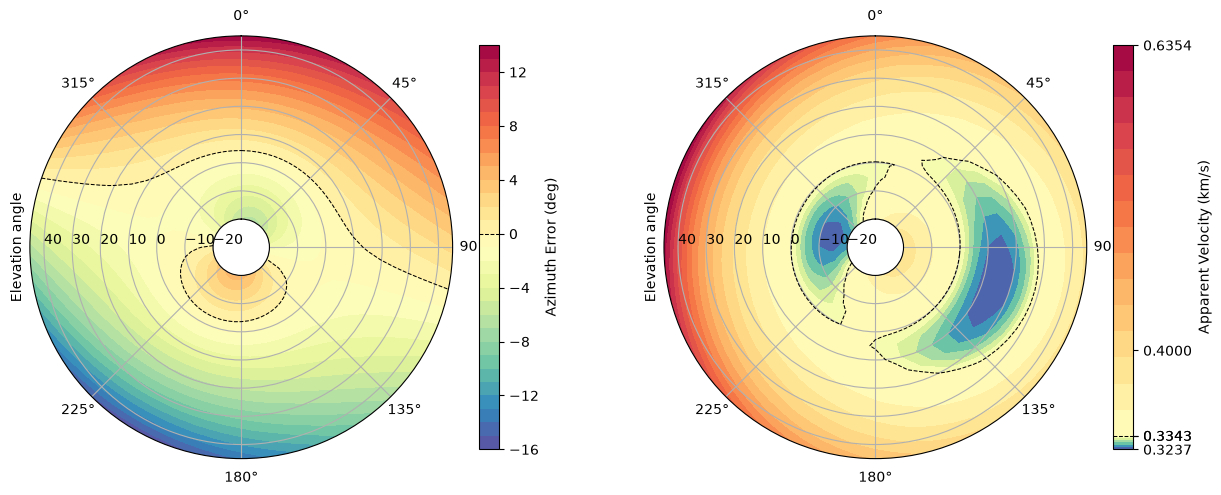

Plotting as incidence angle


Text(0.5, 0.98, 'Incidence Angles')

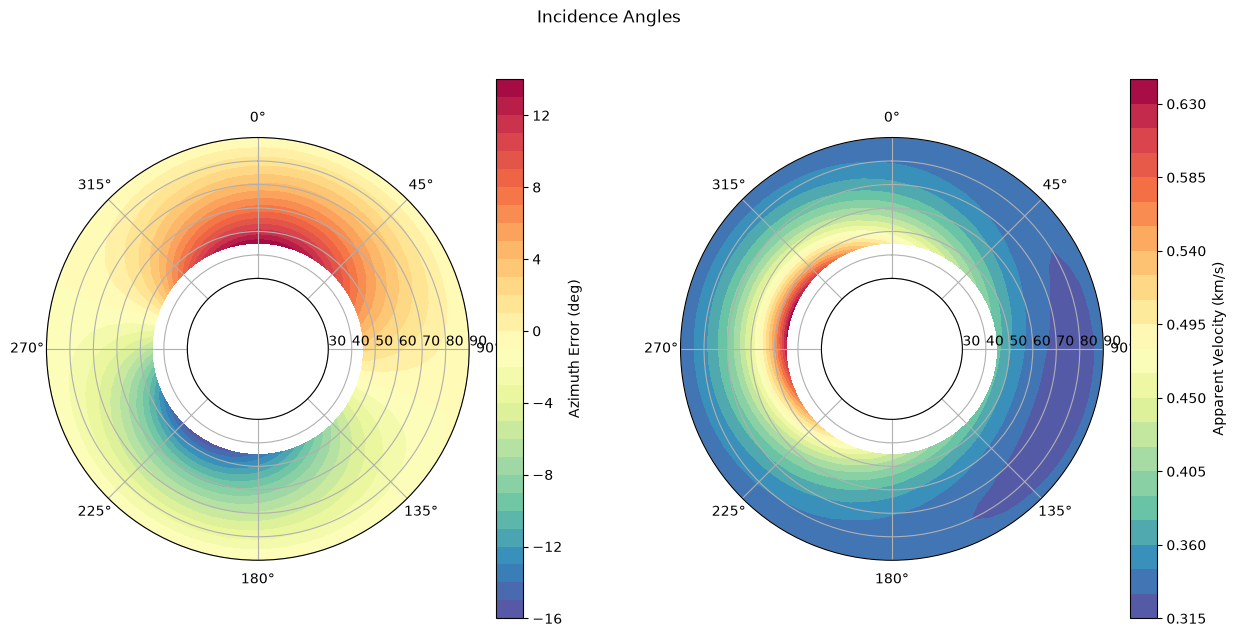

In [8]:
# Plotting! Copy figure 3 from edwards et al 2012
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.colors as mcolors


fig, axs = plt.subplots(ncols=2, figsize=(15,7),subplot_kw={'projection': 'polar'})
for ax in axs:
    ax.set_rlim(-20,45)
    ax.set_rorigin(-30)
    ax.set_theta_zero_location("N")
    ax.set_theta_direction(-1)
    ax.set_rlabel_position(270)
    ax.set_ylabel('Elevation angle')
    #ax.set_rticks((-20,-10,0,10,20))
    ax.set_xticks(np.deg2rad([0,45, 90,135, 180, 225, 315]))

#plot points
#pts = ax.scatter(np.deg2rad(df['azimuth_angle_true']), df['elevation_angle_true'], c=df['Azimuth_error'])

# plot contour:
pivot_el = df.pivot(index='elevation_angle_true', columns='azimuth_angle_true', values='Azimuth_error')
AZg, ELg = np.meshgrid(pivot_el.columns.values, pivot_el.index.values)
Z = pivot_el.values

cont = axs[0].contourf(np.deg2rad(AZg), ELg, Z, levels=30, cmap='Spectral_r',)# vmin=-15, vmax=15)
axs[0].contour(np.deg2rad(AZg), ELg, Z, levels=[0], colors='black', linestyles='--', linewidths=0.75)
cbar = plt.colorbar(cont, ax=axs[0], label='Azimuth Error (deg)', shrink=0.75)
cbar.ax.axhline(0, color='black', linestyle='--', linewidth=0.75)


pivot_el2 = df.pivot(index='elevation_angle_true', columns='azimuth_angle_true', values="lts_velocity_at5C")
AZg, ELg = np.meshgrid(pivot_el2.columns.values, pivot_el2.index.values)
Z2 = pivot_el2.values

#Set up twoslope norm colormap
vcenter = 0.334337
n_below = 5
n_above = 15
levels_below = np.linspace(Z2.min(), vcenter, n_below + 1, endpoint=False)
levels_above = np.linspace(vcenter, Z2.max(), n_above + 1)
levels = np.concatenate([levels_below, levels_above])
vmin = Z2.min()
vmax = Z2.max()
norm = mcolors.TwoSlopeNorm(vmin=vmin, vcenter=vcenter, vmax=vmax)

cont = axs[1].contourf(np.deg2rad(AZg), ELg, Z2, levels=levels, cmap='Spectral_r', norm=norm)
axs[1].contour(np.deg2rad(AZg), ELg, Z2, levels=[0.334337], colors='black', linestyles='--', linewidths=0.75) #add dashed line
#plt.colorbar(cont, ax=axs[1], label='Apparent Velocity (km/s)')
cbar = plt.colorbar(cont, ax=axs[1], ticks=[vmin, vcenter, 0.4, vmax], spacing='proportional', label='Apparent Velocity (km/s)', shrink=0.75)
cbar.ax.axhline(0.334337, color='black', linestyle='--', linewidth=0.75)
cbar.set_ticks(list(cbar.get_ticks()) + [0.334337]) # Add an extra tick at 1
#fig.suptitle("simulated BAEI array response")

plt.show()
plt.close()

print("Plotting as incidence angle")
fig, axs = plt.subplots(ncols=2, figsize=(15,7), subplot_kw={'projection': 'polar'})

for ax in axs:
    ax.set_rlim(30,90)
    ax.set_rorigin(0)
    ax.set_theta_zero_location("N")
    ax.set_theta_direction(-1)
    ax.set_rlabel_position(90)


# plot contour:
pivot_inc = df.pivot(index='incidence_angle', columns='azimuth_angle_true', values='Azimuth_error').sort_index(ascending=False)
AZg, INCg = np.meshgrid(pivot_inc.columns.values, pivot_inc.index.values)
Z = pivot_inc.values

cont = axs[0].contourf(np.deg2rad(AZg), INCg, Z, levels=30, cmap='Spectral_r')
plt.colorbar(cont, ax=axs[0], label='Azimuth Error (deg)')


pivot_inc2 = df.pivot(index='incidence_angle', columns='azimuth_angle_true', values="lts_velocity_at5C").sort_index(ascending=False)
AZg, INCg = np.meshgrid(pivot_inc2.columns.values, pivot_inc2.index.values)
Z2 = pivot_inc2.values

cont = axs[1].contourf(np.deg2rad(AZg), INCg, Z2, levels=30, cmap='Spectral_r')
plt.colorbar(cont, ax=axs[1], label='Apparent Velocity (km/s)')
fig.suptitle("Incidence Angles")





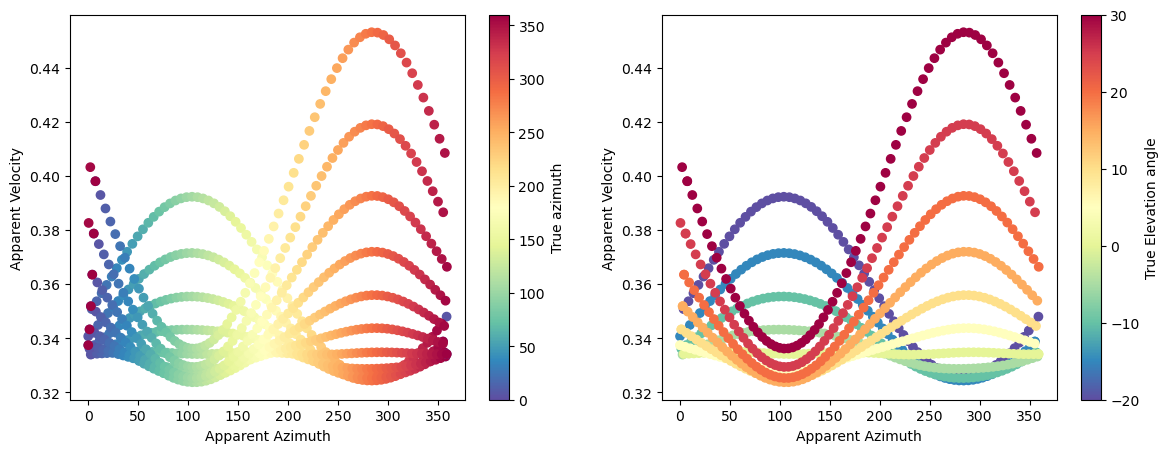

In [4]:


mldf = df[[ "lts_azimuth", "lts_velocity_at5C", 'azimuth_angle_true', 'elevation_angle_true', 'Azimuth_error']]

def trim_below_min_velocity(df):
    """
    For each azimuth_angle_true:
      - find the elevation where lts_velocity_at5C is minimal
      - drop all rows with lower elevation at that azimuth
    """
    og_len = len(df)
    idx = df.groupby("azimuth_angle_true")["lts_velocity_at5C"].idxmin()

    min_elev = (df.loc[idx, ["azimuth_angle_true", "elevation_angle_true"]].set_index("azimuth_angle_true").rename(columns={"elevation_angle_true": "min_elev"}))
    return_df = df.join(min_elev, on="azimuth_angle_true").query("elevation_angle_true >= min_elev").drop(columns="min_elev")
    print(f"{og_len - len(return_df)} rows trimmed")
    return return_df
#mldf = trim_below_min_velocity(mldf)



fig, axs = plt.subplots(ncols=2, figsize=(14,5))
for ax in axs:
    ax.set_xlabel('Apparent Azimuth')
    ax.set_ylabel('Apparent Velocity')
    #ax.set_xlim((180,360))

pts = axs[0].scatter(mldf['lts_azimuth'], mldf['lts_velocity_at5C'], 
            c=mldf['azimuth_angle_true'], cmap='Spectral_r') #data we are trying to interpolate
plt.colorbar(pts, ax=axs[0], label='True azimuth')
pts = axs[1].scatter(mldf['lts_azimuth'], mldf['lts_velocity_at5C'], 
            c=mldf['elevation_angle_true'], cmap='Spectral_r') #data we are trying to interpolate
plt.colorbar(pts, ax=axs[1], label='True Elevation angle')



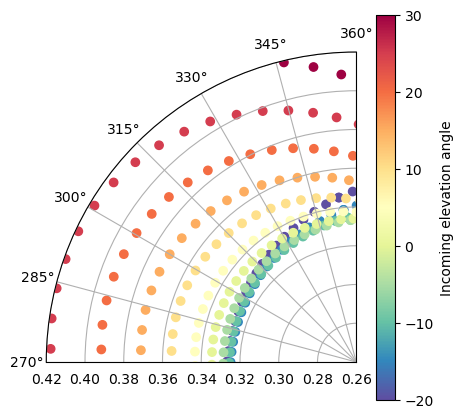

In [6]:
fig, ax = plt.subplots( figsize=(5,5),subplot_kw={'projection': 'polar'})
ax.set_thetamin(270)
ax.set_thetamax(360)
rmin, rmax = 0.26, 0.42
ax.set_rlim(rmin, rmax)

# Polar formatting
ax.set_theta_zero_location("N")
ax.set_theta_direction(-1)
ax.set_rlabel_position(270)

pts = ax.scatter(np.deg2rad(mldf['lts_azimuth']), mldf['lts_velocity_at5C'], c=mldf['elevation_angle_true'], cmap='Spectral_r' )
plt.colorbar(pts, label='Incoming elevation angle')

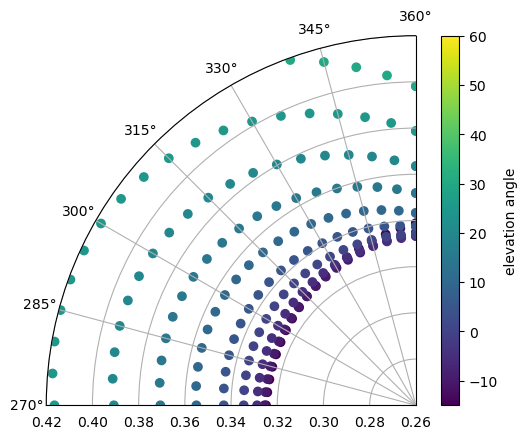

In [102]:
fig, ax = plt.subplots(subplot_kw={'projection': 'polar'})

ax.set_theta_zero_location("N")
ax.set_theta_direction(-1)
ax.set_rlabel_position(90)
ax.set_thetamin(270)
ax.set_thetamax(360)
ax.set_rlim(0.26,0.42)

pts = ax.scatter(np.deg2rad(df['azimuth_angle_true']),df["lts_velocity_at5C"], c=df['elevation_angle_true'] )
plt.colorbar(pts, label="elevation angle")
#cont = ax.tricontourf(np.deg2rad(df['azimuth_angle_true']),df["lts_velocity_at5C"], df['elevation_angle_true'], levels=15)
#plt.colorbar(cont)




#Test if there is a significant atmospheric profile in barry arm
by comparing the temperatures at BAEI and 

Index(['station', 'timestamp', 'airt_c', 'airt_c_avg', 'airt_c_min',
       'airt_c_max', 'rh', 'rh_avg', 'rh_min', 'rh_max', 'dewpt_c',
       'dewpt_c_avg', 'dewpt_c_min', 'dewpt_c_max', 'airt_c_2', 'airt_c_2_avg',
       'airt_c_2_min', 'airt_c_2_max', 'bp_mbar', 'rain_mm_tot', 'ws_ms',
       'ws_ms_avg', 'ws_ms_max', 'winddir', 'ws_ms_s_wvt', 'winddir_d1_wvt',
       'winddir_sd1_wvt', 'windchill_c', 'windchill_c_avg', 'windchill_c_min',
       'windchill_c_max', 'swupper', 'swupper_avg', 'swupper_min',
       'swupper_max', 'swlower', 'swlower_avg', 'swlower_min', 'swlower_max',
       'lwupper', 'lwupper_avg', 'lwupper_min', 'lwupper_max', 'lwlower',
       'lwlower_avg', 'lwlower_min', 'lwlower_max', 'albedo', 'albedo_avg',
       'albedo_min', 'albedo_max', 'rn', 'rn_avg', 'rn_min', 'rn_max',
       'temp005e', 'temp01e', 'temp005', 'temp010', 'temp015', 'temp020',
       'temp025', 'temp030', 'temp040', 'temp050', 'temp070', 'temp100',
       'cumu_rain_mm'],
      dtype='obj

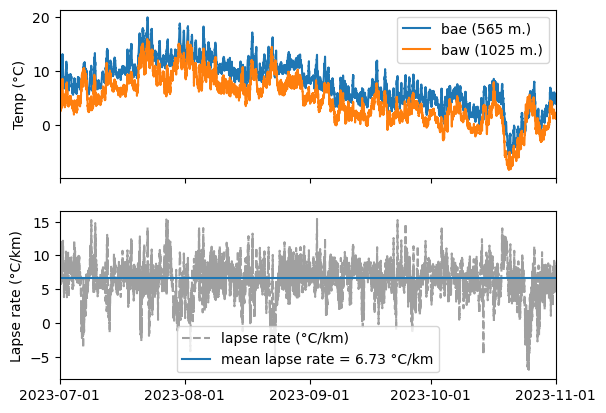

In [41]:
import pandas as pd
import matplotlib.pyplot as plt

bae = pd.read_csv(r"c:\Users\csaunders-shultz\Documents\data\met_data\BAE_met_data.csv", parse_dates=[1], date_format='%m/%d/%y %H:%M')
baw = pd.read_csv(r"c:\Users\csaunders-shultz\Documents\data\met_data\BAW_all_06252025.csv", parse_dates=[1], date_format='%m/%d/%y %H:%M')

t0 = pd.to_datetime("2023-07-01")
t1 = pd.to_datetime("2023-11-01")

bae = bae.loc[(bae["timestamp"] >= t0) & (bae["timestamp"] < t1)]
baw = baw.loc[(baw["timestamp"] >= t0) & (baw["timestamp"] < t1)]
print(baw.columns)
keep_cols = ['timestamp', 'airt_c_avg', 'ws_ms_avg', 'winddir']
bae = bae[keep_cols]
baw = baw[keep_cols]

df = pd.merge(bae, baw, on='timestamp', how='inner', suffixes=['_bae', '_baw'])
df.head()
bae_alt = 565 #,
baw_alt = 1025 #m
df['lapse_rate'] = 1000* (df['airt_c_avg_bae'] - df['airt_c_avg_baw']) / (baw_alt-bae_alt) # °C/km
fig, axs = plt.subplots(nrows=2)
axs[0].plot(df['timestamp'], df['airt_c_avg_bae'], label='bae (565 m.)')
axs[0].plot(df['timestamp'], df['airt_c_avg_baw'], label='baw (1025 m.)')
axs[0].legend()
axs[0].set_xticks([pd.to_datetime(f"2023-{m}-01") for m in ['07', '08', '09', '10', '11',]])
axs[0].set_xticklabels(())
axs[0].set_ylabel('Temp (°C)')


ax2=axs[1]
ax2.plot(df['timestamp'], df['lapse_rate'], c='gray', ls='--', alpha=0.75, label='lapse rate (°C/km)')
ax2.axhline(6.73, label="mean lapse rate = 6.73 °C/km")
print(df['lapse_rate'].mean)
ax2.set_xticks([pd.to_datetime(f"2023-{m}-01") for m in ['07', '08', '09', '10', '11',]])
ax2.set_ylabel('Lapse rate (°C/km)')

for ax in axs:
    ax.set_xlim(t0,t1)
plt.legend()

# 

22.25
27.09
21.91
22.87


(-0.5, 3310.5, 5949.5, -0.5)

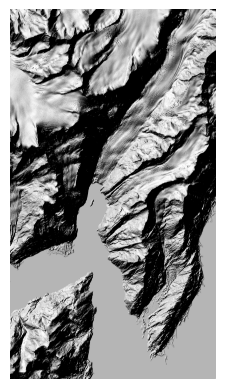

In [19]:
#READ IN IFSAR DEM, which has the barry island in it. 
#FROM THAT, GET elevation for BAIS stations!
import pyproj.transformer
import xarray as xr
import pyproj
import numpy as np
import rasterio
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt



#Generate spherical dataset
#Get UTM baei array center
lat_list = [61.132675, 61.132085, 61.13173, 61.131875, 61.132405, 61.13218]
lon_list = [-148.1219, -148.12107, -148.121985, -148.122915, -148.12281, -148.12206]
elev_list = [591.8, 607.6, 597.6, 584.6, 582.0, 596.2]
elev_from_ifsar_dem = [594.8, 600.57, 591.29, 576.88, 574.12, 590.06]

#bais array
bais_stations = {'BAIS.01': (61.11962, -148.158315), 'BAIS.02': (61.119775, -148.157485), 
 'BAIS.03': (61.11939, -148.1579), 'BAIS.04': (61.119575, -148.157775)}
#lat_list = [61.11962, 61.119775, 61.11939, 61.119575, ]
#lon_list = [-148.158315, -148.157485, -148.1579, -148.157775]
#elev_list = [9.5, 9.5, 9.5, 9.5] #REALLY INACCURATE
elev_from_ifsar_dem = [22.25, 27.09, 21.91, 22.87]

#trans = pyproj.Transformer.from_crs("EPSG:4326", "EPSG:32606", always_xy=True) # WGS84 lat long
#baei_array = np.vstack([trans.transform(lon_list, lat_list), elev_list])
#baei_mean = np.mean(baei_array, axis=1)
#print(baei_mean)
def hillshade(dem, azimuth=315, altitude=45):
    az = np.deg2rad(azimuth)
    alt = np.deg2rad(altitude)

    dy, dx = np.gradient(dem)
    slope = np.pi / 2.0 - np.arctan(np.sqrt(dx*dx + dy*dy))
    aspect = np.arctan2(-dx, dy)

    hs = (np.sin(alt) * np.sin(slope) +
          np.cos(alt) * np.cos(slope) * np.cos(az - aspect))

    return np.clip(hs, 0, 1)

dem_file =r"C:\Users\csaunders-shultz\Documents\data\elevation_data\IFSAR_dem\dds4\ifsar\dsm\DSM_N6100W14815\DSM_N6100W14815.tif"
trans = pyproj.Transformer.from_crs("EPSG:4326", "EPSG:3338", always_xy=True)
with rasterio.open(dem_file) as src:
    dem = src.read(1)          # (y, x)
    transform = src.transform
    crs = src.crs
    for k, (lat, lon) in bais_stations.items():
    #for lat, lon in zip(lat_list, lon_list):
        x, y = trans.transform(lon, lat)
        elev = list(src.sample([(x, y)]))[0][0]
        print(elev)

    #Now plot 

plt.imshow(hillshade(dem), cmap="gray")
plt.axis("off")





In [ ]:
dem.shape

(0, 0)